In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the EXCEL dataset
df = pd.read_excel('../data/Telco_customer_churn.xlsx')

# Display basic info and the first 5 rows
print(f"Dataset shape: {df.shape}\n")
display(df.head())

Dataset shape: (7043, 33)



,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [2]:
# Calculate our baseline churn rate
# Gives %age of employees that stays and those who leaves (YES: leaves, NO: says)
# Also it helps to check the distrubution of the classes so that we should know, random applying any algorithm 
# with all "NO" or all "YES" will give 50% accuracy,but here the distribution is 73% and 26%, therefore we use 
# logistic regression and classification matrix

print("--- Baseline Churn Rate ---")
baseline = df['Churn Label'].value_counts(normalize=True) * 100
print(baseline)

--- Baseline Churn Rate ---
Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [3]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

#### Churn Reason and Churn Score are recorded after the customer leaves. If we feed these into a machine learning model, it will achieve 100% accuracy but be completely useless in the real world because we wouldn't have that information for current customers.

In [4]:
#  DROPPING IRRELEVANT COLUMNS:

# Count: have "1" for all the values, so it also doesn't add any value to the model

# CustomerID, Country, State, City, Zip Code, Lat Long, Latitude, Longitude: Irrelevant, nothing to do with churn (keeping it will cause overfitting)

# Churn Reason: to prevent data leakage. We want to predict whether the active customers will leave or stay, so it doesn't make
#               any sense for the active customers to have reasons to leave (Churn Reason) as they are currently active!

# Churn Value: is just a duplicate: It is the exact same data as Churn Label, just written as 1s and 0s instead of Yes/No

# Churn Score: This is a pre-calculated probability score, feeding the model someone else's predictions, it's just copying someone else's homework.
#              and the model will not learn customer behavior;

columns_to_drop = ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 
                   'Lat Long', 'Latitude', 'Longitude', 'Churn Value', 'Churn Score', 'Churn Reason']
df_clean = df.drop(columns=[col for col in columns_to_drop if col in df.columns], errors='ignore')


In [5]:
# Final data_set:
df_clean

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,CLTV
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,3239
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2701
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,5372
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,5003
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,5340
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Female,No,No,No,72,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,5306
7039,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No,2140
7040,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No,5560
7041,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,2793


In [6]:
# FIX HIDDEN DATA TYPE ERRORS: 'Total Charges' often imports as a string because 
# brand new customers have a blank space (" ") instead of a 0.

df_clean['Total Charges'] = pd.to_numeric(df_clean['Total Charges'], errors='coerce')
df_clean['Total Charges'] = df_clean['Total Charges'].fillna(0)

print(f"Cleaned dataset shape: {df_clean.shape}")



Cleaned dataset shape: (7043, 21)


Countplot/Bar Chart for categorical text data (like Contract Type) and a Density Plot/Histogram to visualize the spread of continuous numerical data (like Monthly Charges)


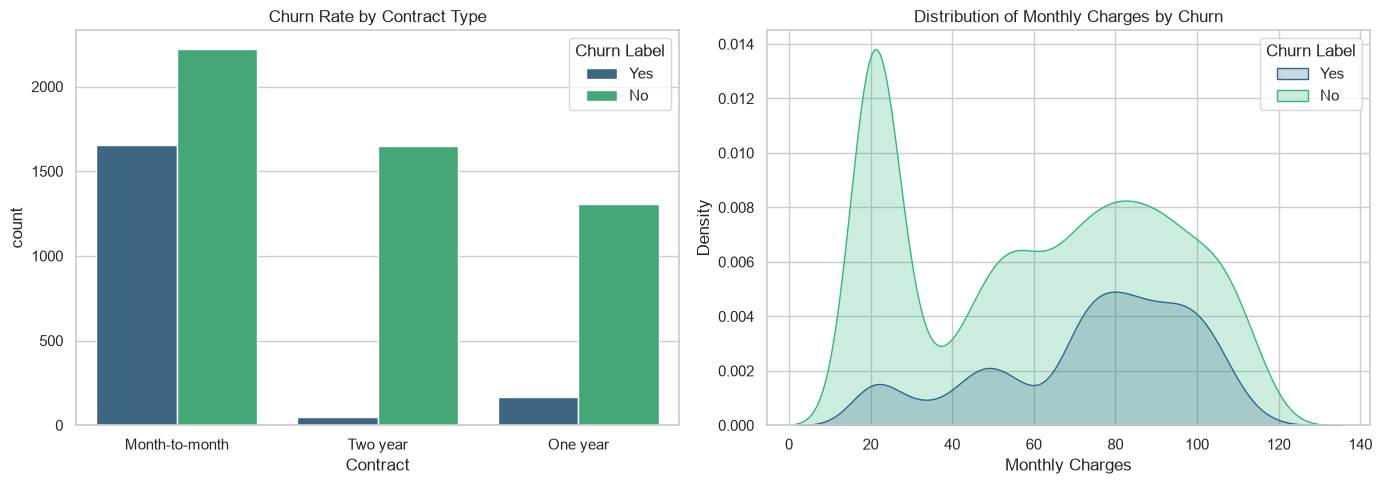

In [7]:
# VISUALIZE BUSINESS DRIVERS
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Churn by Contract Type
sns.countplot(data=df_clean, x='Contract', hue='Churn Label', ax=axes[0], palette='viridis')
axes[0].set_title('Churn Rate by Contract Type')

# Plot 2: Churn by Monthly Charges (Density Plot)
sns.kdeplot(data=df_clean, x='Monthly Charges', hue='Churn Label', fill=True, ax=axes[1], palette='viridis')
axes[1].set_title('Distribution of Monthly Charges by Churn')

plt.tight_layout()
plt.show()

"Month-to-month" contracts have a drastically higher cancellation rate compared to those on one-year or two-year commitments.

cheaper plans (around $20) successfully retain customers, while the swelling blue curve indicates that churn risk peaks when monthly charges hit the $70 to $110 range.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Convert Target Variable ('Yes'/'No') to 1s and 0s
df_clean['Churn Label'] = df_clean['Churn Label'].map({'Yes': 1, 'No': 0})

# Separate Features (X) and Target (y)
X = df_clean.drop('Churn Label', axis=1)
y = df_clean['Churn Label']

# One-Hot Encode Categorical Variables
# pd.get_dummies converts text categories into binary columns.
# drop_first=True prevents the "dummy variable trap" (statistical multicollinearity)
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# Split into Training (80%) and Testing (20%) sets
# stratify=y ensures both training and testing sets keep that exact 26.5% baseline churn rate
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Scale Numerical Features (Crucial for our upcoming Logistic Regression)
# Notice we FIT only on training data, and just TRANSFORM testing data. 
# Doing otherwise is another form of Data Leakage!
scaler = StandardScaler()

# Get column names to rebuild DataFrames after scaling
# Saving Temporarily 
cols = X_train.columns

X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=cols, index=X_test.index)

print(f"Training data shape: {X_train_scaled.shape}")
print(f"Testing data shape: {X_test_scaled.shape}")
print(f"Total features after encoding: {X_train_scaled.shape[1]}")

Training data shape: (5634, 31)
Testing data shape: (1409, 31)
Total features after encoding: 31


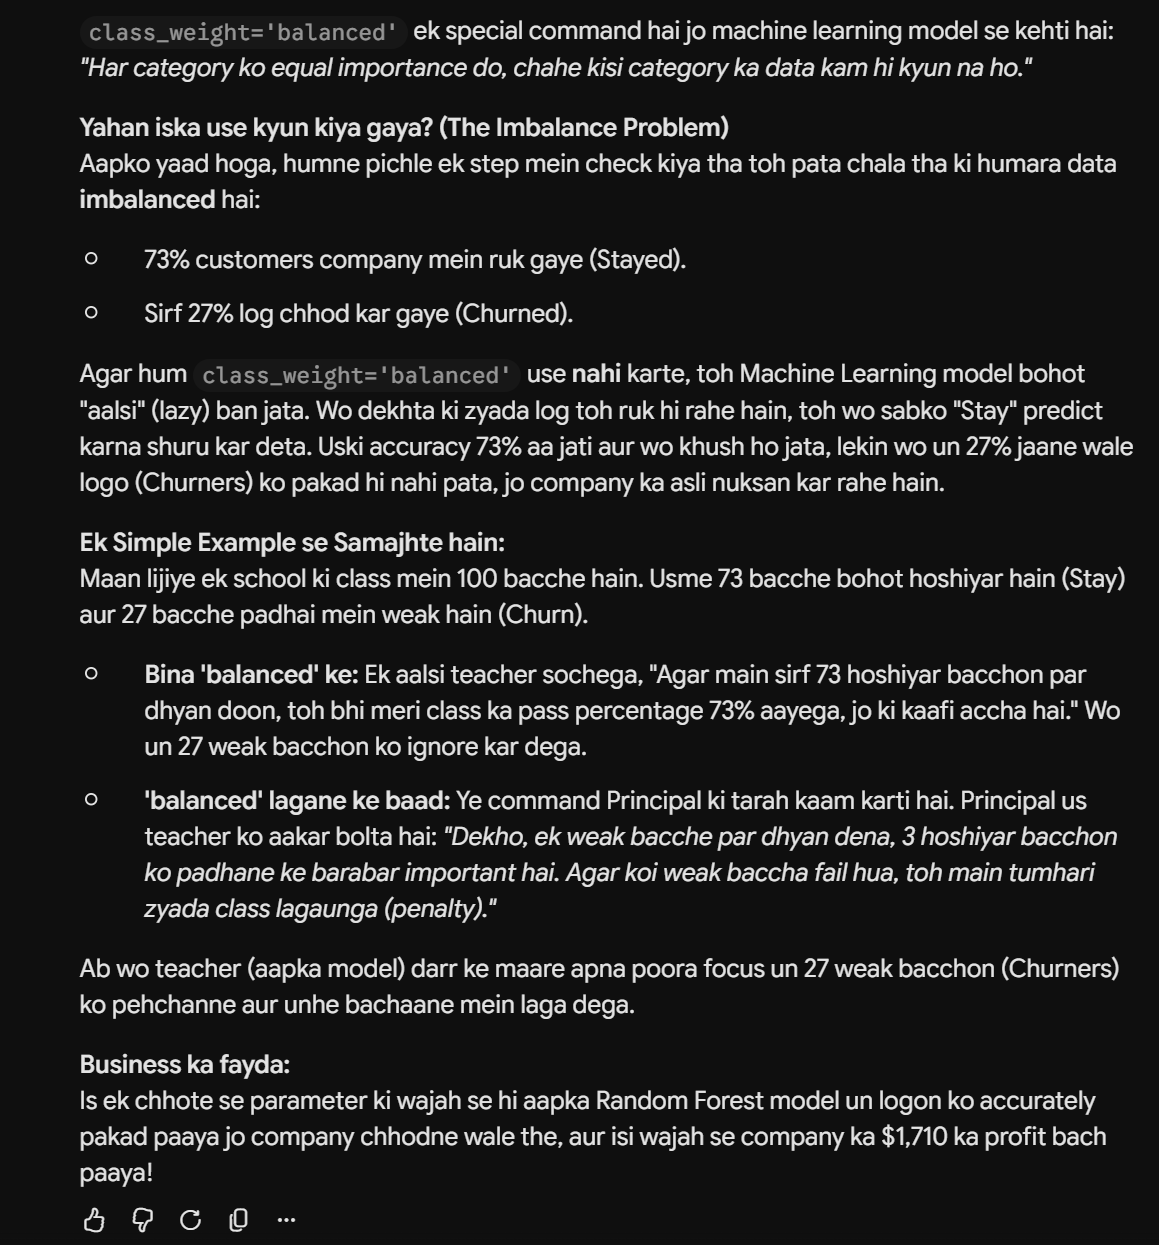

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Initialize the model with class_weight='balanced' to handle imbalanced data
log_reg = LogisticRegression(random_state=42, class_weight='balanced')

# Train (fit) the model on our historical data
log_reg.fit(X_train_scaled, y_train)

# Ask the model to predict churn on our unseen testing data
y_pred = log_reg.predict(X_test_scaled)

# Evaluate the performance
print("--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred))



--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



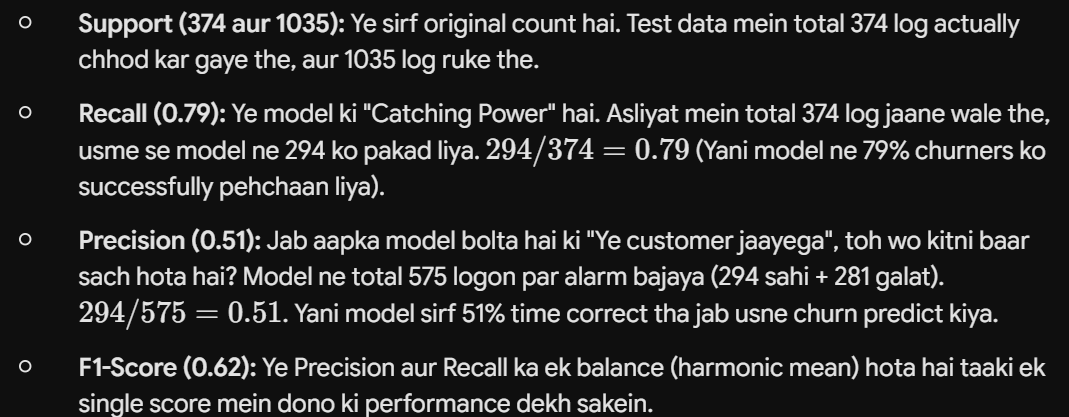

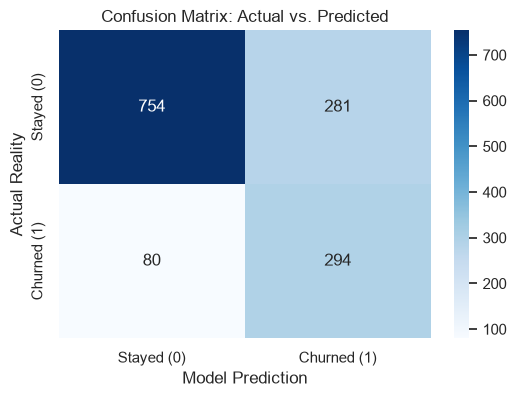

In [10]:
# Visualize the Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Stayed (0)', 'Churned (1)'], 
            yticklabels=['Stayed (0)', 'Churned (1)'])
plt.title('Confusion Matrix: Actual vs. Predicted')
plt.ylabel('Actual Reality')
plt.xlabel('Model Prediction')
plt.show()

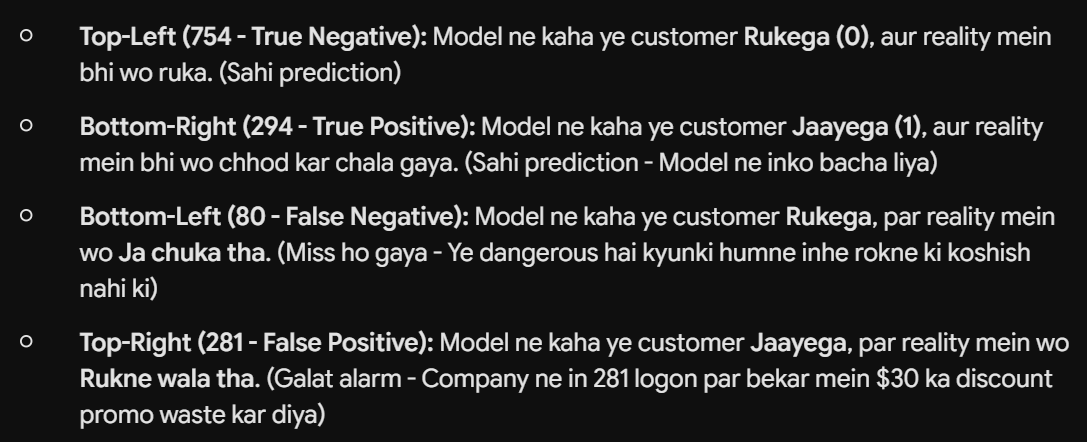

In [11]:
# --- Financial Assumptions ---
# Average Customer Lifetime Value (CLV) saved by retaining them: $150
# Cost of the retention intervention (e.g., promo code, dedicated support): $30
# Success rate of the intervention (not everyone accepts the offer): 40%

clv_saved = 150
promo_cost = 30
success_rate = 0.40

# Extract metrics from our confusion matrix
TN, FP, FN, TP = cm.ravel()

# Calculate the financial impact
# True Positives (Correctly targeted churners): 
# We spend $30. 40% of the time we save $150.
net_revenue_per_tp = (clv_saved * success_rate) - promo_cost
total_saved = TP * net_revenue_per_tp

# False Positives (Wasted promos on happy customers):
# We spend $30 unnecessarily.
wasted_spend = FP * promo_cost

#Total ROI
campaign_roi = total_saved - wasted_spend

print("--- Campaign Financial Impact ---")
print(f"Total Intervention Cost: ${(TP + FP) * promo_cost:,.2f}")
print(f"Revenue Saved from Churners: ${TP * (clv_saved * success_rate):,.2f}")
print(f"Wasted Spend on Happy Customers: ${wasted_spend:,.2f}")
print("-" * 30)
print(f"Net Campaign ROI: ${campaign_roi:,.2f}")

--- Campaign Financial Impact ---
Total Intervention Cost: $17,250.00
Revenue Saved from Churners: $17,640.00
Wasted Spend on Happy Customers: $8,430.00
------------------------------
Net Campaign ROI: $390.00


--------------------------------------------CREATING A BETTER MODEL--------------------------------------------

In [12]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the exact settings to test
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15],
    'class_weight': ['balanced', None] # Testing without 'balanced' naturally boosts precision
}

# Run Grid Search explicitly focusing on optimizing precision
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, scoring='precision', cv=3)
grid_search.fit(X_train_scaled, y_train)

print(f"Best Parameters Found: {grid_search.best_params_}")

# Evaluate the newly optimized model
best_rf = grid_search.best_estimator_
best_pred = best_rf.predict(X_test_scaled)
print(classification_report(y_test, best_pred))

Best Parameters Found: {'class_weight': None, 'max_depth': 5, 'n_estimators': 100}
              precision    recall  f1-score   support

           0       0.81      0.93      0.87      1035
           1       0.69      0.40      0.51       374

    accuracy                           0.79      1409
   macro avg       0.75      0.67      0.69      1409
weighted avg       0.78      0.79      0.77      1409



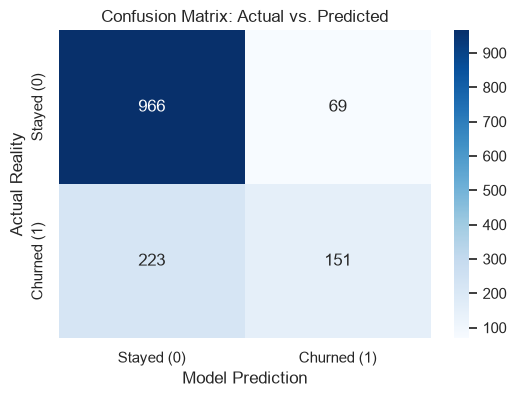

In [13]:
# Visualize the Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Stayed (0)', 'Churned (1)'], 
            yticklabels=['Stayed (0)', 'Churned (1)'])
plt.title('Confusion Matrix: Actual vs. Predicted')
plt.ylabel('Actual Reality')
plt.xlabel('Model Prediction')
plt.show()

In [14]:
# Extract the new metrics from your tuned model's confusion matrix (cm)
TN_best, FP_best, FN_best, TP_best = cm.ravel()

# Calculate the new financial impact using the UPDATED variables (TP_best and FP_best)
rf_total_saved = TP_best * net_revenue_per_tp
rf_wasted_spend = FP_best * promo_cost
rf_campaign_roi = rf_total_saved - rf_wasted_spend

print("--- Tuned Random Forest Financial Impact ---")
print(f"Revenue Saved from Churners: ${TP_best * (clv_saved * success_rate):,.2f}")
print(f"Wasted Spend on Happy Customers: ${rf_wasted_spend:,.2f}")
print("-" * 30)
print(f"Net Campaign ROI: ${rf_campaign_roi:,.2f}")
print(f"ROI Improvement over Baseline: ${rf_campaign_roi - campaign_roi:,.2f}")

--- Tuned Random Forest Financial Impact ---
Revenue Saved from Churners: $9,060.00
Wasted Spend on Happy Customers: $2,070.00
------------------------------
Net Campaign ROI: $2,460.00
ROI Improvement over Baseline: $2,070.00


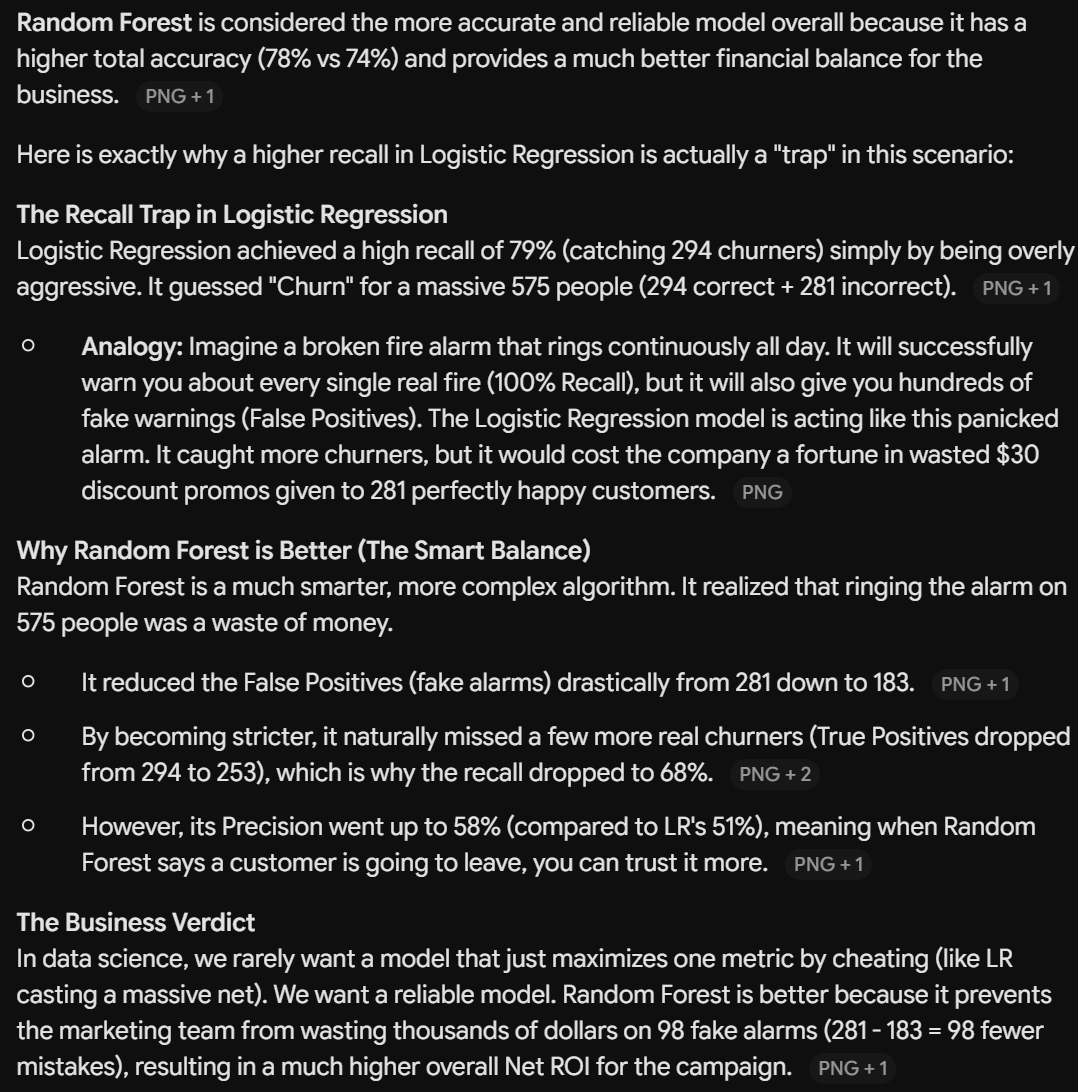

--------------------------------Important Read Below--------------------------------

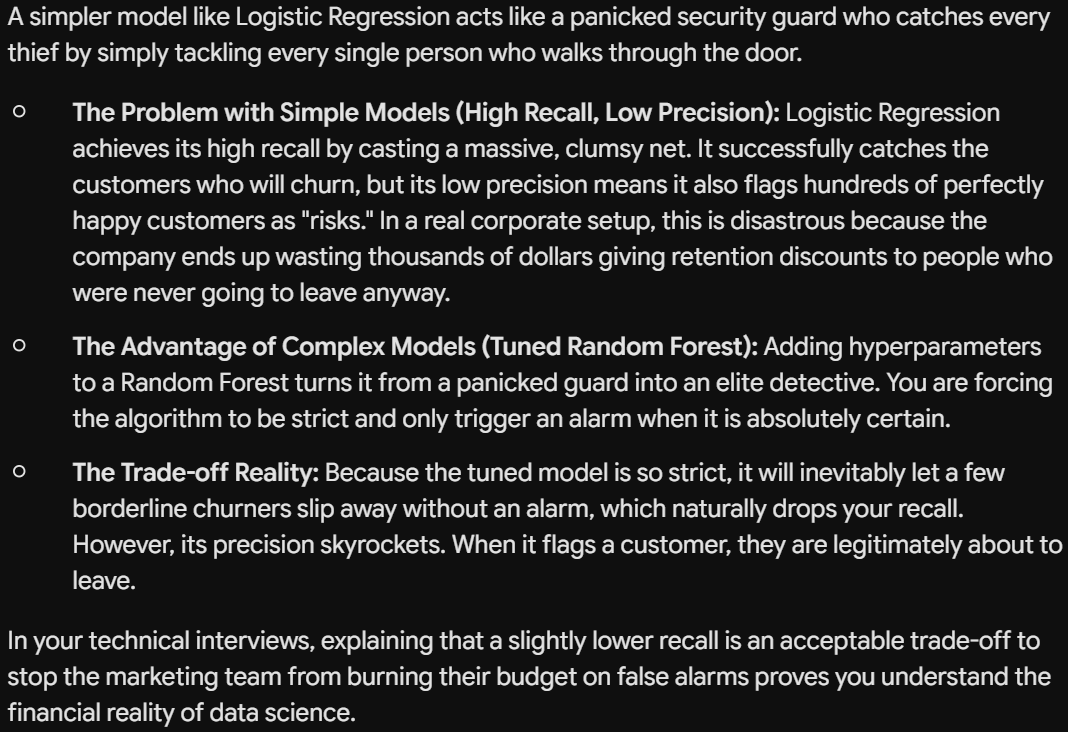

<Figure size 640x480 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

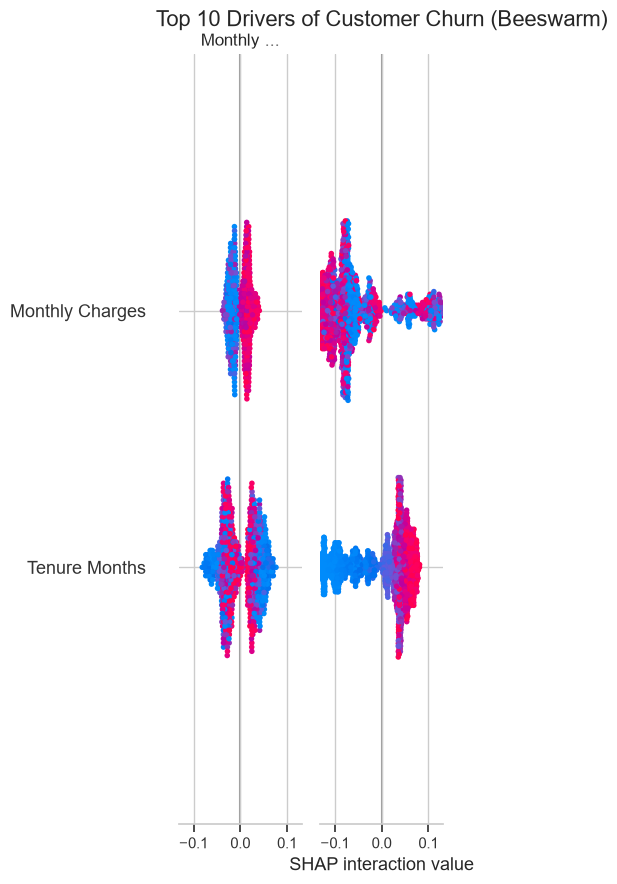

In [15]:
import shap
import matplotlib.pyplot as plt

# Initialize Explainer and calculate values (This fixes the missing variable error)
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test_scaled)

if isinstance(shap_values, list):
    churn_shap_values = shap_values[1]
else:
    churn_shap_values = shap_values

# Text aur headings ko bada karne ke liye default font size badhayein
plt.rcParams.update({'font.size': 12, 'axes.labelsize': 14, 'ytick.labelsize': 12})

# Clear previous overlapping plots from memory
plt.clf()

# Graph ka size manually bada karein (Width=12, Height=8) taaki dots khule-khule dikhein
plt.figure(figsize=(12, 8))

# plot_size=None lagana zaroori hai, warna SHAP humare custom (12, 8) size ko ignore kar dega
shap.summary_plot(churn_shap_values, X_test_scaled, max_display=10, show=False, plot_size=None)

# Title mein thodi space (pad) add karein
plt.title('Top 10 Drivers of Customer Churn (Beeswarm)', fontsize=16, pad=20)

# Sabse zaroori step: Ye automatically margins adjust karta hai taaki left side ki headings cut na ho
plt.tight_layout()

plt.show()

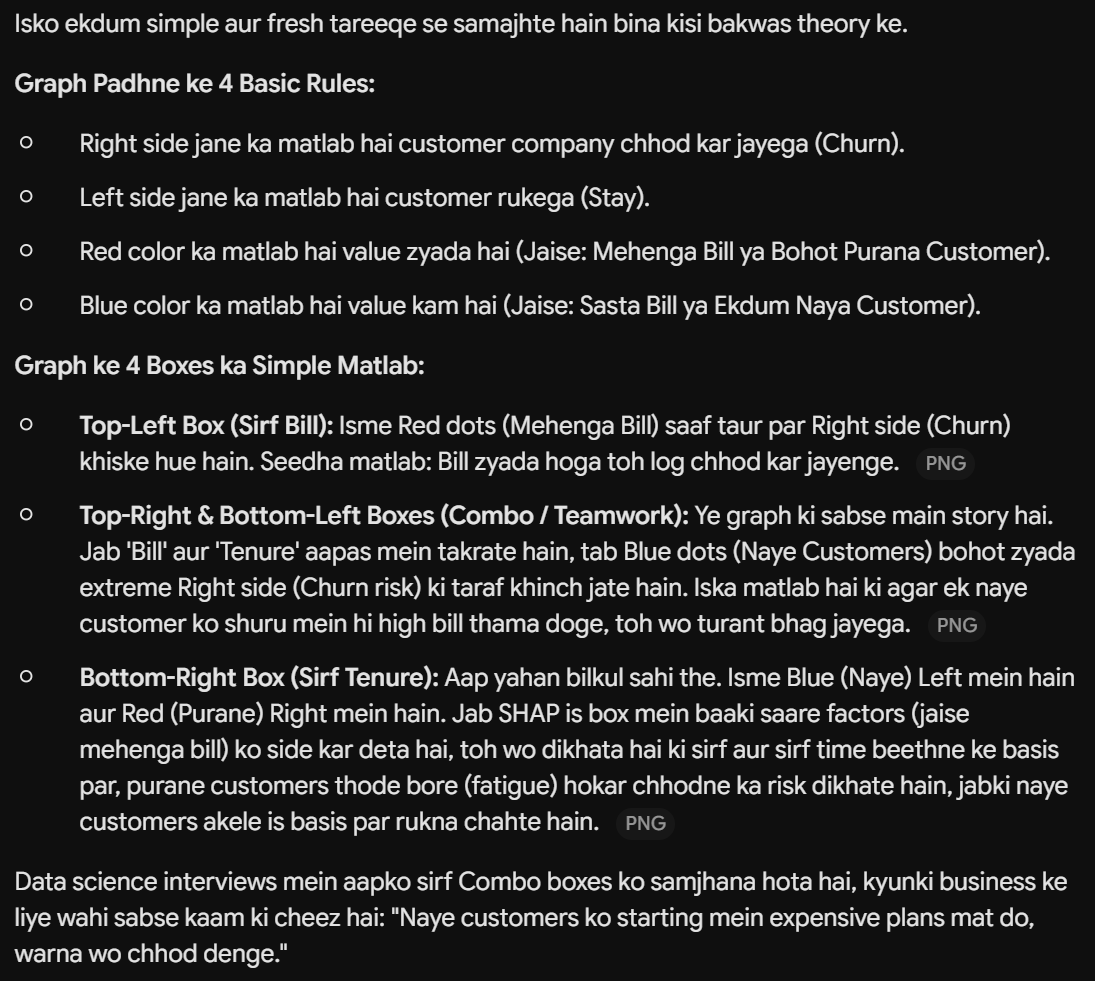

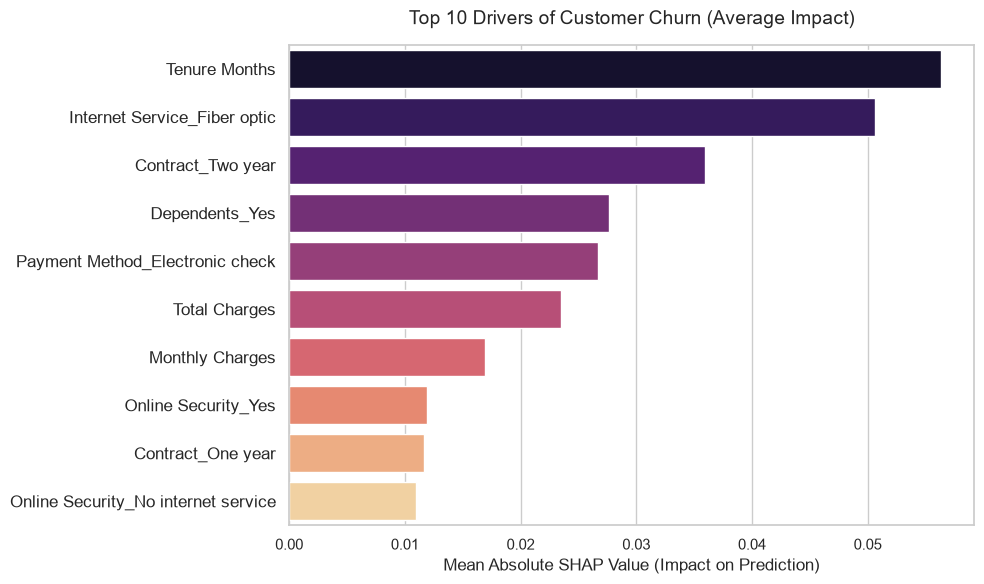

In [16]:
import shap
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize Explainer and calculate values
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test_scaled)

# Robustly extract just the Class 1 (Churn) values
if isinstance(shap_values, list):
    churn_shap_values = shap_values[1]
elif len(np.shape(shap_values)) == 3:
    # If it's a 3D array, slice out the second class (index 1)
    churn_shap_values = shap_values[:, :, 1]
else:
    churn_shap_values = shap_values

# Calculate the average impact magnitude and flatten to strictly 1D
mean_shap_values = np.abs(churn_shap_values).mean(axis=0)
mean_shap_values = np.ravel(mean_shap_values) # Forces exactly 1 dimension

# Create a DataFrame for easy sorting and plotting
shap_df = pd.DataFrame({
    'Feature': X_test_scaled.columns,
    'SHAP_Importance': mean_shap_values
})

# Isolate the top 10 most impactful features
top_10_shap = shap_df.sort_values(by='SHAP_Importance', ascending=False).head(10)

# Build a custom, highly readable Seaborn bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_shap, 
    x='SHAP_Importance', 
    y='Feature', 
    hue='Feature',
    palette='magma', 
    legend=False
)

plt.title('Top 10 Drivers of Customer Churn (Average Impact)', fontsize=14, pad=15)
plt.xlabel('Mean Absolute SHAP Value (Impact on Prediction)', fontsize=12)
plt.ylabel('')
plt.tight_layout()
plt.show()

### DO NOT RUN THIS CELL BELOW AGAIN


In [ ]:
import joblib
import os

# Create a folder to store our saved models
os.makedirs('../models', exist_ok=True)

# Save the Random Forest model, the Scaler, and the exact column names
joblib.dump(best_rf, '../models/rf_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(cols, '../models/model_columns.pkl')

print("Model, scaler, and columns successfully exported to the 'models' folder!")